# Chapter 6: Distance Measures and the Curse of Dimensionality

Vector search needs a precise notion of a "best match". Embeddings are compared with a
similarity score, where larger is better. Perceptual features such as color histograms
are compared with a distance, where smaller is better. This demo works through both
views and then asks what happens to them when vectors have hundreds or thousands of
dimensions.

The demo has two parts:

- **Part 1** follows book section 6.1 *Distance and Similarity Measures*: dot product
  versus cosine, why the query length does not matter, how distances and scores relate on
  the unit sphere, and how to keep the dimensions of a perceptual feature comparable.
- **Part 2** follows book section 6.3 *The Curse of Dimensionality* (optional background
  reading): it reproduces the book's Monte Carlo numbers and ends with real embeddings
  from the TREC-COVID collection.

**Prerequisites:** Chapter 4 (vector space model) and Chapter 5 (embeddings).

## Setup

In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from shared.display import print_table, display_md

# Part 1: Comparing Vectors

## Dot product and cosine similarity

The dot product sums the products of matching components. Cosine similarity divides that
sum by the two vector lengths, so only the direction counts:

$$\text{sim}_{\text{dot}}(\mathbf{q}, \mathbf{d}_i) = \mathbf{q} \cdot \mathbf{d}_i
\qquad
\text{sim}_{\text{cos}}(\mathbf{q}, \mathbf{d}_i) = \frac{\mathbf{q} \cdot \mathbf{d}_i}{\lVert \mathbf{q} \rVert \, \lVert \mathbf{d}_i \rVert}$$

We use a query and five documents in 2D so that we can draw them. Document `d1` points
almost exactly in the query direction but is short; `d2` is long and less aligned.

In [2]:
q = np.array([2.0, 1.0])
docs = {
    "d1": np.array([1.8, 1.0]),
    "d2": np.array([4.0, 4.0]),
    "d3": np.array([1.0, 3.0]),
    "d4": np.array([3.0, -0.5]),
    "d5": np.array([-2.0, 1.0]),
}
names = list(docs)
D = np.array(list(docs.values()))

dot = D @ q
cos = dot / (np.linalg.norm(D, axis=1) * np.linalg.norm(q))

def ranks(scores, descending=True):
    """Rank position (1 = best) of every entry."""
    order = np.argsort(-scores if descending else scores)
    r = np.empty(len(scores), dtype=int)
    r[order] = np.arange(1, len(scores) + 1)
    return r

print_table(
    [[n, f"{np.linalg.norm(v):.2f}", f"{dt:.2f}", rd, f"{c:+.3f}", rc]
     for n, v, dt, rd, c, rc in zip(names, D, dot, ranks(dot), cos, ranks(cos))],
    headers=["Doc", "Length", "Dot", "Rank (dot)", "Cosine", "Rank (cos)"],
)

| Doc   |   Length |   Dot |   Rank (dot) |   Cosine |   Rank (cos) |
|:------|---------:|------:|-------------:|---------:|-------------:|
| d1    |     2.06 |   4.6 |            4 |    0.999 |            1 |
| d2    |     5.66 |  12   |            1 |    0.949 |            2 |
| d3    |     3.16 |   5   |            3 |    0.707 |            4 |
| d4    |     3.04 |   5.5 |            2 |    0.809 |            3 |
| d5    |     2.24 |  -3   |            5 |   -0.6   |            5 |

The two measures disagree. Cosine puts `d1` first because it has the smallest angle to the
query. The dot product puts the long vector `d2` first and drops `d1` to rank 4. Document
`d5` lies in the half-space opposite the query and scores negatively under both.

The book's figure of the cone and the hyperplane shows the same thing geometrically. The
plot below draws the region that holds the top 2 documents under each measure.

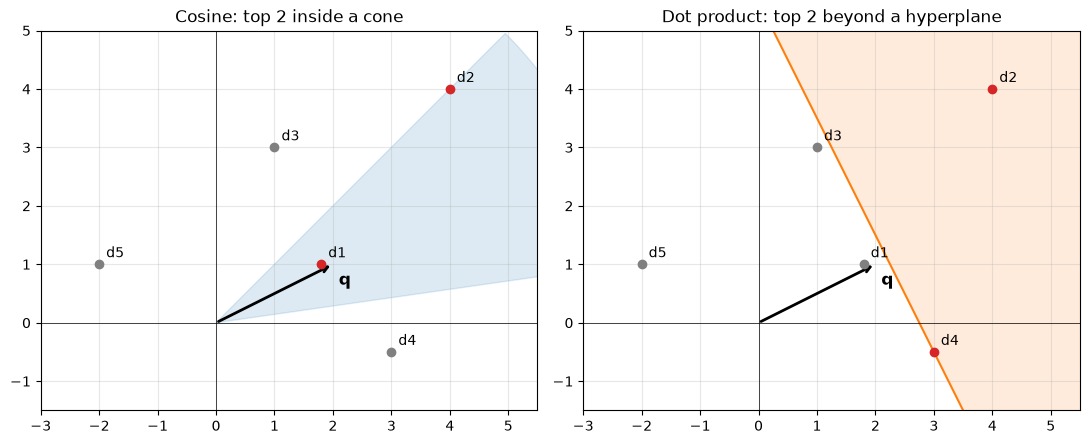

In [3]:
def plot_cone_and_hyperplane(q, docs, k=2):
    names, D = list(docs), np.array(list(docs.values()))
    q_hat = q / np.linalg.norm(q)
    cos = D @ q_hat / np.linalg.norm(D, axis=1)
    dot = D @ q
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))

    # Left: a cone around q whose half-angle reaches the k-th best cosine.
    half = np.arccos(np.sort(cos)[-k])
    phi = np.arctan2(q[1], q[0])
    arc = np.linspace(phi - half, phi + half, 50)
    axes[0].fill(np.r_[0, 7 * np.cos(arc)], np.r_[0, 7 * np.sin(arc)],
                 color="tab:blue", alpha=0.15)
    axes[0].set_title(f"Cosine: top {k} inside a cone")

    # Right: the hyperplane q . x = t through the k-th best dot product.
    t = np.sort(dot)[-k]
    base, along = t * q / (q @ q), np.array([-q_hat[1], q_hat[0]])
    line = np.array([base - 9 * along, base + 9 * along])
    axes[1].fill(*np.r_[line, line[::-1] + 9 * q_hat].T, color="tab:orange", alpha=0.15)
    axes[1].plot(*line.T, color="tab:orange")
    axes[1].set_title(f"Dot product: top {k} beyond a hyperplane")

    for ax, scores in zip(axes, [cos, dot]):
        top = set(np.argsort(-scores)[:k])
        ax.annotate("", xy=q, xytext=(0, 0), arrowprops=dict(arrowstyle="->", lw=2))
        ax.text(*(q + [0.1, -0.35]), "q", fontsize=12, weight="bold")
        for i, (n, v) in enumerate(zip(names, D)):
            ax.scatter(*v, color="tab:red" if i in top else "gray", zorder=3)
            ax.text(*(v + [0.12, 0.12]), n)
        ax.axhline(0, color="black", lw=0.5)
        ax.axvline(0, color="black", lw=0.5)
        ax.set_xlim(-3, 5.5)
        ax.set_ylim(-1.5, 5)
        ax.set_aspect("equal")
        ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

plot_cone_and_hyperplane(q, docs)

## The query length does not matter

Most embedding models output unit-length vectors. If not, we normalize every document
vector once before indexing, $\hat{\mathbf{d}}_i = \mathbf{d}_i / \lVert \mathbf{d}_i \rVert$.
The index then only computes dot products, and the query needs no normalization:

$$\text{sim}_{\text{cos}}(\mathbf{q}, \mathbf{d}_i) = \frac{1}{\lVert \mathbf{q} \rVert}\; \mathbf{q} \cdot \hat{\mathbf{d}}_i$$

We check this and also scale the query by 10. Scaling changes every score by the same
factor, so the ranking stays the same.

In [4]:
D_hat = D / np.linalg.norm(D, axis=1, keepdims=True)
s_raw = D_hat @ q
s_scaled = D_hat @ (10 * q)
s_cos = s_raw / np.linalg.norm(q)

print_table(
    [[n, f"{c:+.4f}", f"{a:+.3f}", f"{b:+.2f}", f"{x:+.4f}"]
     for n, c, a, b, x in zip(names, cos, s_raw, s_scaled, s_cos)],
    headers=["Doc", "Cosine", "q · d̂", "10q · d̂", "q · d̂ / ‖q‖"],
)
order = lambda s: " > ".join(names[i] for i in np.argsort(-s))
display_md(
    f"- Ranking by cosine: {order(cos)}\n"
    f"- Ranking by $\\mathbf{{q}} \\cdot \\hat{{\\mathbf{{d}}}}_i$: {order(s_raw)}\n"
    f"- Ranking by $10\\mathbf{{q}} \\cdot \\hat{{\\mathbf{{d}}}}_i$: {order(s_scaled)}"
)

| Doc   |   Cosine |   q · d̂ |   10q · d̂ |   q · d̂ / ‖q‖ |
|:------|---------:|--------:|----------:|--------------:|
| d1    |   0.9991 |   2.234 |     22.34 |        0.9991 |
| d2    |   0.9487 |   2.121 |     21.21 |        0.9487 |
| d3    |   0.7071 |   1.581 |     15.81 |        0.7071 |
| d4    |   0.8087 |   1.808 |     18.08 |        0.8087 |
| d5    |  -0.6    |  -1.342 |    -13.42 |       -0.6    |

- Ranking by cosine: d1 > d2 > d4 > d3 > d5
- Ranking by $\mathbf{q} \cdot \hat{\mathbf{d}}_i$: d1 > d2 > d4 > d3 > d5
- Ranking by $10\mathbf{q} \cdot \hat{\mathbf{d}}_i$: d1 > d2 > d4 > d3 > d5

All three rankings agree, and the last column reproduces the cosine exactly. Normalizing the
query only matters when scores must be comparable across queries, for example against a
fixed threshold.

## Distances and scores on the unit sphere

A distance reverses the direction of comparison: smaller is better. On the unit sphere,
the squared Euclidean distance is a linear function of the dot product:

$$\lVert \hat{\mathbf{q}} - \hat{\mathbf{d}}_i \rVert^2 = 2 - 2\, \hat{\mathbf{q}} \cdot \hat{\mathbf{d}}_i$$

So ranking by increasing Euclidean distance gives the same order as ranking by decreasing
cosine. A decreasing function such as $1/(1 + \delta)$ turns the distance back into a
score, again without changing the order.

In [5]:
q_hat = q / np.linalg.norm(q)
dist = np.linalg.norm(D_hat - q_hat, axis=1)
sim = 1 / (1 + dist)

print_table(
    [[n, f"{c:+.4f}", f"{dd ** 2:.4f}", f"{2 - 2 * c:.4f}", f"{s:.4f}"]
     for n, c, dd, s in zip(names, cos, dist, sim)],
    headers=["Doc", "q̂ · d̂", "‖q̂ − d̂‖²", "2 − 2 q̂ · d̂", "1 / (1 + δ)"],
)
display_md(
    f"- Ranking by decreasing cosine: {order(cos)}\n"
    f"- Ranking by increasing distance: {' > '.join(names[i] for i in np.argsort(dist))}\n"
    f"- Ranking by $1/(1+\\delta)$: {order(sim)}"
)

| Doc   |   q̂ · d̂ |   ‖q̂ − d̂‖² |   2 − 2 q̂ · d̂ |   1 / (1 + δ) |
|:------|--------:|-----------:|--------------:|--------------:|
| d1    |  0.9991 |     0.0019 |        0.0019 |        0.9584 |
| d2    |  0.9487 |     0.1026 |        0.1026 |        0.7574 |
| d3    |  0.7071 |     0.5858 |        0.5858 |        0.5665 |
| d4    |  0.8087 |     0.3825 |        0.3825 |        0.6179 |
| d5    | -0.6    |     3.2    |        3.2    |        0.3586 |

- Ranking by decreasing cosine: d1 > d2 > d4 > d3 > d5
- Ranking by increasing distance: d1 > d2 > d4 > d3 > d5
- Ranking by $1/(1+\delta)$: d1 > d2 > d4 > d3 > d5

## Neighborhood shapes

Each distance defines its own neighborhood: the set of points within distance 1 of a
center. Euclidean distance (L2) gives a circle, Manhattan distance (L1) a diamond, and the
maximum distance (L-infinity) a square. A quadratic distance
$(\mathbf{x} - \mathbf{c})^\top \mathbf{A} (\mathbf{x} - \mathbf{c})$ weights and correlates
the dimensions and gives a tilted ellipse.

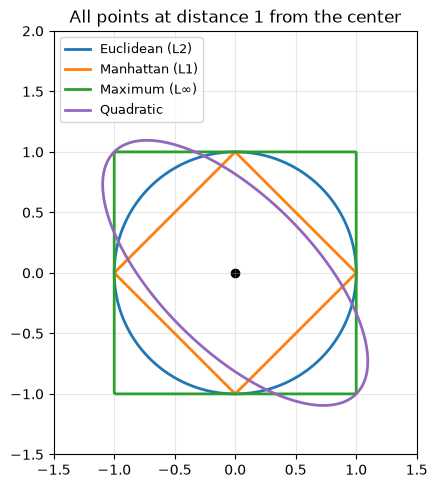

In [6]:
A_quad = np.array([[1.5, 1.0], [1.0, 1.5]])
xs = np.linspace(-1.5, 1.5, 401)
ys = np.linspace(-1.5, 2, 401)
X, Y = np.meshgrid(xs, ys)
P = np.stack([X, Y], axis=-1)

shapes = {
    "Euclidean (L2)": np.sqrt(X ** 2 + Y ** 2),
    "Manhattan (L1)": np.abs(X) + np.abs(Y),
    "Maximum (L∞)": np.maximum(np.abs(X), np.abs(Y)),
    "Quadratic": np.sqrt(np.einsum("...i,ij,...j->...", P, A_quad, P)),
}

fig, ax = plt.subplots(figsize=(5.5, 5.5))
for (label, values), color in zip(shapes.items(), ["tab:blue", "tab:orange", "tab:green", "tab:purple"]):
    ax.contour(X, Y, values, levels=[1.0], colors=color, linewidths=2)
    ax.plot([], [], color=color, lw=2, label=label)
ax.scatter(0, 0, color="black")
ax.set_aspect("equal")
ax.set_title("All points at distance 1 from the center")
ax.legend(loc="upper left", fontsize=9)
ax.grid(alpha=0.3)
plt.show()

## A perceptual feature: color histograms

The book turns an image into a vector by counting colors. For each channel (red, green,
blue) we count how many pixels have each of the 256 intensities: $3 \times 256 = 768$
counts. Exact intensities are too fine, so we quantize each channel into 16 wide bins and
get a 48-dimensional feature vector.

To have a small image collection, we cut the two sample photographs into tiles of
$200 \times 200$ pixels. Tiles `M..` come from the Matterhorn, tiles `F..` from a tennis
photograph.

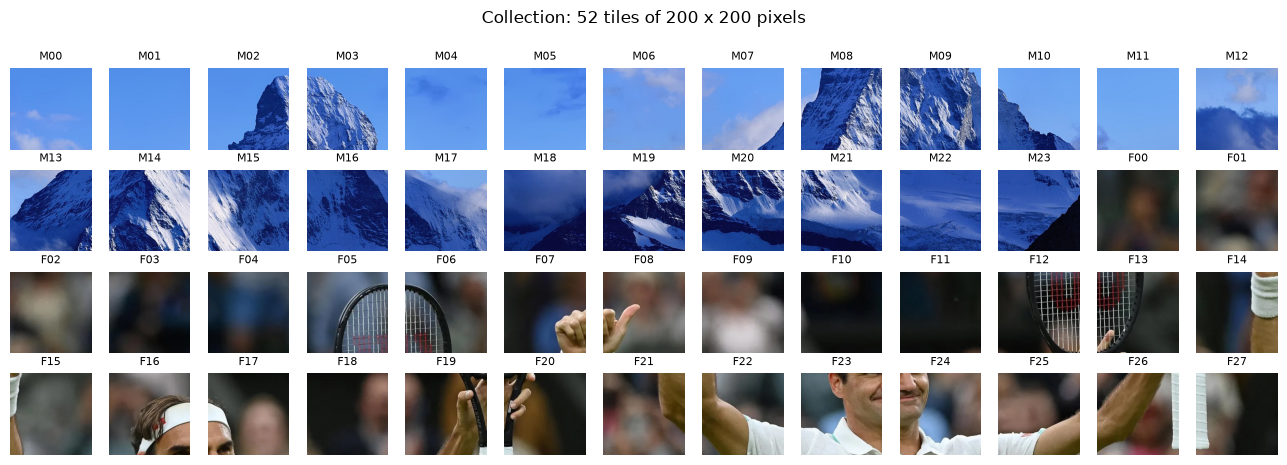

In [7]:
TILE = 200

def load_tiles(path, prefix, size=TILE):
    """Cut an image into non-overlapping size x size tiles."""
    img = plt.imread(path)
    rows, cols = img.shape[0] // size, img.shape[1] // size
    return {f"{prefix}{r * cols + c:02d}": img[r * size:(r + 1) * size, c * size:(c + 1) * size]
            for r in range(rows) for c in range(cols)}

tiles = {**load_tiles("data/images/matterhorn.jpg", "M"),
         **load_tiles("data/images/federer.jpg", "F")}
tile_names = list(tiles)

fig, axes = plt.subplots(4, 13, figsize=(13, 4.6))
for ax, name in zip(axes.flat, tile_names):
    ax.imshow(tiles[name])
    ax.set_title(name, fontsize=8)
    ax.axis("off")
plt.suptitle(f"Collection: {len(tiles)} tiles of {TILE} x {TILE} pixels", y=1.0)
plt.tight_layout()
plt.show()

We first look at the full 768-bin histograms of one tile, then at its quantized
48-dimensional version.

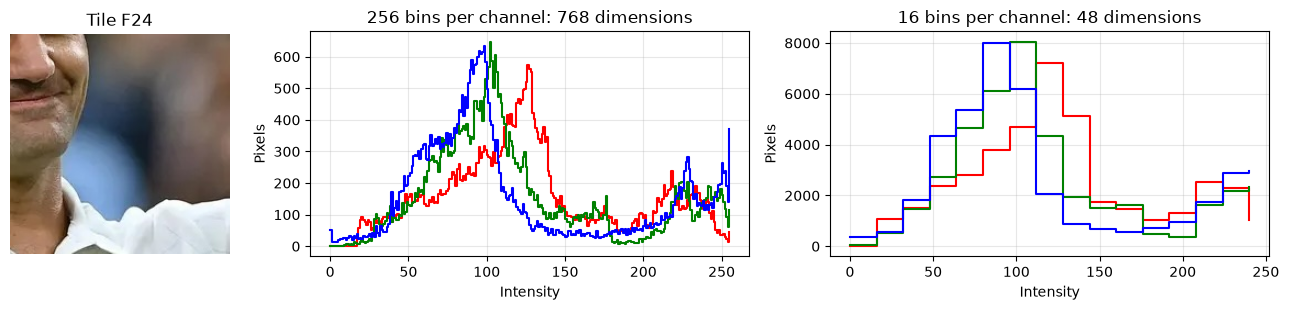

In [8]:
def color_histogram(img, bins=16):
    """Concatenated per-channel histograms with `bins` equal-width bins each."""
    width = 256 // bins
    return np.concatenate([np.bincount(img[..., ch].ravel() // width, minlength=bins)
                           for ch in range(3)])

example = tiles["F24"]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2), gridspec_kw={"width_ratios": [1, 2, 2]})
axes[0].imshow(example)
axes[0].set_title("Tile F24")
axes[0].axis("off")
for bins, ax in [(256, axes[1]), (16, axes[2])]:
    h = color_histogram(example, bins).reshape(3, bins)
    for counts, color in zip(h, ["red", "green", "blue"]):
        ax.plot(np.arange(bins) * 256 / bins, counts, color=color, drawstyle="steps-post")
    ax.set_title(f"{bins} bins per channel: {3 * bins} dimensions")
    ax.set_xlabel("Intensity")
    ax.set_ylabel("Pixels")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Ranking tiles by Manhattan distance

To compare two tiles, we sum the absolute differences of their 48 counts. This is the
Manhattan distance. Tiles with similar colors receive a small distance.

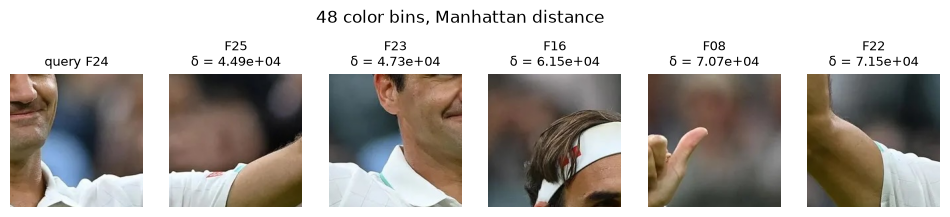

In [9]:
H = np.array([color_histogram(tiles[n]) for n in tile_names], dtype=float)

def manhattan(F, i):
    return np.abs(F - F[i]).sum(axis=1)

def show_neighbors(query, F, distance=manhattan, k=5, title=""):
    """Show the query tile and its k nearest tiles under the given distance."""
    i = tile_names.index(query)
    dist = distance(F, i)
    nearest = [j for j in np.argsort(dist) if j != i][:k]
    fig, axes = plt.subplots(1, k + 1, figsize=(2 * (k + 1), 2.4))
    for ax, j in zip(axes, [i] + nearest):
        ax.imshow(tiles[tile_names[j]])
        ax.set_title(f"query {query}" if j == i else f"{tile_names[j]}\nδ = {dist[j]:,.3g}",
                     fontsize=9)
        ax.axis("off")
    plt.suptitle(title, y=1.04)
    plt.show()
    return [tile_names[j] for j in nearest]

top_l1 = show_neighbors("F24", H, title="48 color bins, Manhattan distance")

The nearest tiles all show the tennis player: skin tones, a white shirt, and a dark
background.

The book stresses that the comparison function belongs to the feature. What happens if we
replace the Manhattan distance with cosine similarity on the same bins? We first count,
for every tile as the query, how many of the top 5 tiles the two measures share.

In [10]:
def cosine_distance(F, i):
    Fn = F / np.linalg.norm(F, axis=1, keepdims=True)
    return 1 - Fn @ Fn[i]

def top_k(F, i, distance, k=5):
    """Set of the k nearest tiles to tile i, excluding the tile itself."""
    return set([j for j in np.argsort(distance(F, i)) if j != i][:k])

shared = [len(top_k(H, i, manhattan) & top_k(H, i, cosine_distance))
          for i in range(len(tile_names))]
display_md(
    f"**Shared tiles in the top 5, Manhattan vs. cosine:** {np.mean(shared):.1f} of 5 on average "
    f"over {len(tile_names)} queries (lowest: {min(shared)} of 5)"
)

**Shared tiles in the top 5, Manhattan vs. cosine:** 4.0 of 5 on average over 52 queries (lowest: 2 of 5)

On most tiles the two measures largely agree. Histograms that are almost identical stay
close under any reasonable measure. The differences show where a tile mixes colors. Tile
M03 shows a snowy peak against the sky:

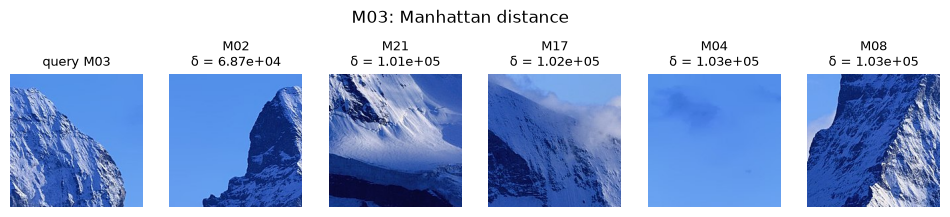

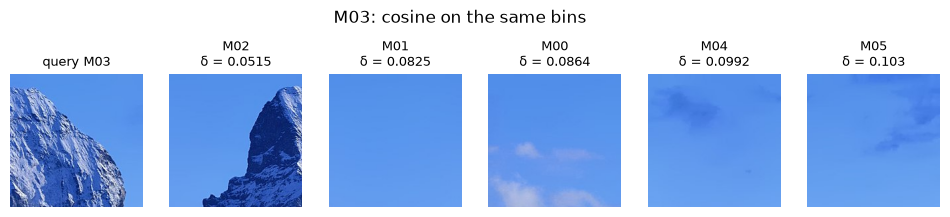

In [11]:
show_neighbors("M03", H, title="M03: Manhattan distance")
show_neighbors("M03", H, distance=cosine_distance, title="M03: cosine on the same bins");

Manhattan distance returns other peaks with snow and rock. Cosine returns mostly plain sky.
The reason is how each measure weights the bins. Cosine works with products of counts, so
the few large bins dominate: here the big blue-sky bin decides the ranking. Manhattan
distance adds up every bin difference linearly, so the smaller snow and rock bins still
count. The two measures answer different questions, and only the design of the feature
can say which one is right.

## Keeping dimensions comparable: image size

Bin counts depend on the image size. We enlarge tile F24 to twice its width and height.
It shows exactly the same scene with the same color distribution, but it has four times as
many pixels and therefore four times larger counts.

In [12]:
big = np.repeat(np.repeat(tiles["F24"], 2, axis=0), 2, axis=1)
h_small, h_big = color_histogram(tiles["F24"]), color_histogram(big)
i24 = tile_names.index("F24")
nearest_other = np.sort(manhattan(H, i24))[1]

normalize = lambda h: h / (h.sum() / 3)  # each channel's bins sum to 1
display_md(
    f"| Comparison | Manhattan distance |\n"
    f"|---|---|\n"
    f"| F24 vs. its enlarged copy, raw counts | {np.abs(h_small - h_big).sum():,.0f} |\n"
    f"| F24 vs. its nearest other tile, raw counts | {nearest_other:,.0f} |\n"
    f"| F24 vs. its enlarged copy, normalized | {np.abs(normalize(h_small) - normalize(h_big)).sum():.3f} |"
)

| Comparison | Manhattan distance |
|---|---|
| F24 vs. its enlarged copy, raw counts | 360,000 |
| F24 vs. its nearest other tile, raw counts | 44,872 |
| F24 vs. its enlarged copy, normalized | 0.000 |

With raw counts, the enlarged copy looks less similar than any other tile in the
collection. The fix is the same as for long documents in the vector space model: divide
every count by the number of pixels. Each channel then holds fractions that sum to 1, and
the copy has distance 0.

## Keeping dimensions comparable: mixing features

Now we append the average brightness of each tile, on a scale from 0 to 255, to the 48
normalized bins. The bins of each channel sum to 1, so the Manhattan distance over all
48 bins can never exceed 6. A brightness difference of 50 alone outweighs any color
difference.

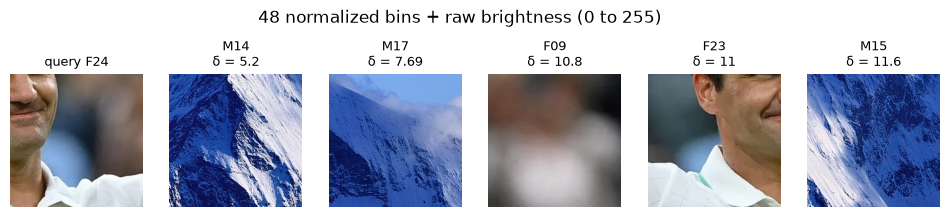

**Share of the distance that comes from brightness:** 93% (1 of 49 dimensions)

In [13]:
Hn = H / (TILE * TILE)
brightness = np.array([tiles[n].mean() for n in tile_names])
mixed = np.column_stack([Hn, brightness])

def brightness_share(F, i):
    """Fraction of the total Manhattan distance that comes from the last dimension."""
    return np.abs(F[:, -1] - F[i, -1]).sum() / manhattan(F, i).sum()

top_mixed = show_neighbors("F24", mixed, title="48 normalized bins + raw brightness (0 to 255)")
display_md(f"**Share of the distance that comes from brightness:** "
           f"{brightness_share(mixed, i24):.0%} (1 of {mixed.shape[1]} dimensions)")

Brightness now decides almost everything. The nearest tiles are bright snow fields from
the Matterhorn, not the tennis player. **Gaussian normalization** gives every dimension a
fair share. For each dimension $j$, we subtract the mean $\mu_j$ and divide by the
standard deviation $\sigma_j$, both estimated once from the collection:

$$\hat{v}_j = \frac{v_j - \mu_j}{\sigma_j}$$

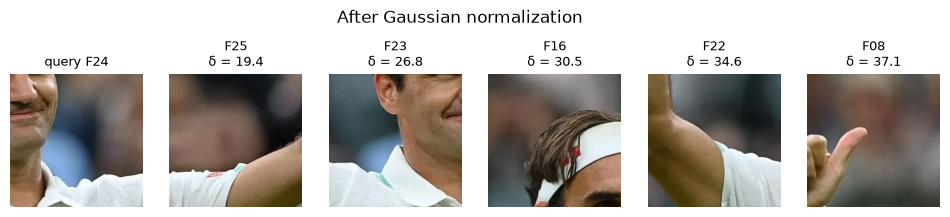

**Share of the distance that comes from brightness:** 2%  
**Overlap with the color-only top 5:** 5 of 5 (raw brightness: 1 of 5)

In [14]:
mu = mixed.mean(axis=0)
sigma = mixed.std(axis=0)
sigma[sigma == 0] = 1.0  # bins that are empty in every tile carry no information
gauss = (mixed - mu) / sigma

top_gauss = show_neighbors("F24", gauss, title="After Gaussian normalization")
display_md(
    f"**Share of the distance that comes from brightness:** {brightness_share(gauss, i24):.0%}  \n"
    f"**Overlap with the color-only top 5:** {len(set(top_gauss) & set(top_l1))} of 5 "
    f"(raw brightness: {len(set(top_mixed) & set(top_l1))} of 5)"
)

After normalization, brightness contributes about as much as any one of the 49
dimensions, and the tennis tiles return. The statistics $\mu_j$ and $\sigma_j$ come from
the whole collection, not from one query, so a tile always maps to the same normalized
vector.

## Quadratic distance through whitening

Gaussian normalization treats the dimensions as independent. A quadratic distance
$(\mathbf{q} - \mathbf{p})^\top \mathbf{A} (\mathbf{q} - \mathbf{p})$ also models
correlations through a positive semi-definite matrix $\mathbf{A}$. Evaluating it for every
candidate is expensive. With the eigenvalue decomposition
$\mathbf{A} = \mathbf{V} \boldsymbol{\Lambda} \mathbf{V}^\top$, we map every vector once
with $\mathbf{W} = \boldsymbol{\Lambda}^{1/2} \mathbf{V}^\top$. The quadratic distance in
the original space becomes a plain squared Euclidean distance in the transformed space.

We take correlated 2D data and use the inverse of its covariance matrix as $\mathbf{A}$.

In [15]:
rng = np.random.default_rng(3)
data = rng.multivariate_normal([0, 0], [[1.0, 0.8], [0.8, 1.0]], size=500)
A = np.linalg.inv(np.cov(data.T))

eigval, V = np.linalg.eigh(A)
W = np.diag(np.sqrt(eigval)) @ V.T
white = data @ W.T

pairs = [(0, 1), (2, 3), (4, 5), (6, 7)]
rows = []
for i, j in pairs:
    diff = data[i] - data[j]
    rows.append([f"p{i}, p{j}", f"{diff @ A @ diff:.6f}",
                 f"{np.sum((white[i] - white[j]) ** 2):.6f}"])
print_table(rows, headers=["Pair", "Quadratic distance (original)", "Squared L2 (whitened)"])

| Pair   |   Quadratic distance (original) |   Squared L2 (whitened) |
|:-------|--------------------------------:|------------------------:|
| p0, p1 |                         6.69028 |                 6.69028 |
| p2, p3 |                         2.45133 |                 2.45133 |
| p4, p5 |                        14.6095  |                14.6095  |
| p6, p7 |                         0.68692 |                 0.68692 |

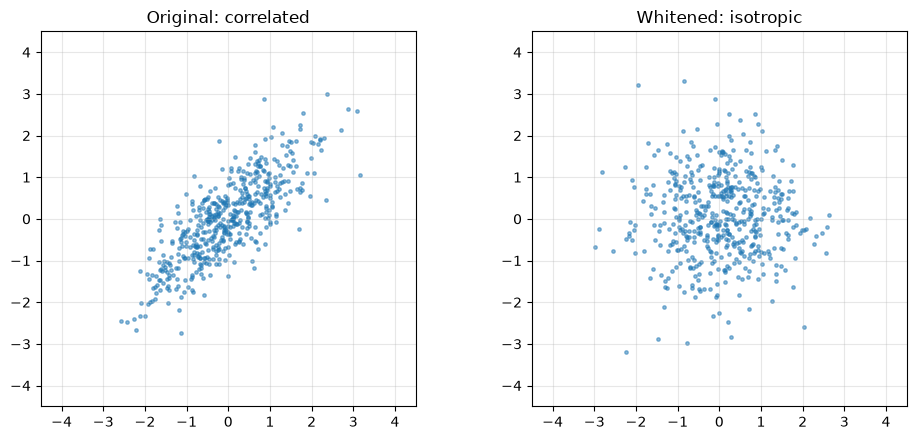

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
for ax, pts, title in [(axes[0], data, "Original: correlated"),
                       (axes[1], white, "Whitened: isotropic")]:
    ax.scatter(pts[:, 0], pts[:, 1], s=6, alpha=0.5)
    ax.set_title(title)
    ax.set_aspect("equal")
    ax.set_xlim(-4.5, 4.5)
    ax.set_ylim(-4.5, 4.5)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

The two columns agree to the last digit. The index stores the whitened vectors and answers
quadratic-distance queries with ordinary Euclidean distance.

# Part 2: The Curse of Dimensionality

<div style="border-left: 4px solid #0284C7; background: rgba(2, 132, 199, 0.06); padding: 0.6em 0.9em; margin: 0.6em 0; border-radius: 4px;">
<strong style="color:#0284C7; text-transform:uppercase; font-size:0.78em; letter-spacing:0.06em;">Optional background</strong><br>
This part follows book section 6.3, which is optional background reading and not assessed. Section 6.4 only needs its conclusions: in high dimensions, trees cannot prune, and the exact nearest neighbor is not worth chasing.
</div>

## Distances grow with the dimension

The book places a point $\mathbf{p}$ with value 0.4 in every dimension next to the center
$\mathbf{c}$ of the unit cube, which has value 0.5 in every dimension. Their distance is
$0.1\sqrt{d}$, and the farthest corner of the cube is $0.6\sqrt{d}$ away from
$\mathbf{p}$. A sphere of radius 3 around $\mathbf{p}$ covers the whole square in 2D:

| Dimensions $d$ | $\delta(\mathbf{p}, \mathbf{c}) = 0.1\sqrt{d}$ | Farthest corner $0.6\sqrt{d}$ | Inside radius 3 |
|---|---|---|---|
| 2 | 0.14 | 0.85 | whole cube |
| 25 | 0.50 | 3.00 | whole cube (just) |
| 100 | 1.00 | 6.00 | center, not the corners |
| 900 | 3.00 | 18.00 | center on the boundary |
| 1000 | 3.16 | 18.97 | not even the center |

## Distances lose their contrast

The book measures the **contrast** between the farthest and the nearest point,
$(\delta_{\max} - \delta_{\min}) / \delta_{\min}$, for 10,000 uniform points in the unit
cube, averaged over 50 random queries. We run the same experiment.

In [17]:
def contrast_table(dims, n_points=10_000, n_queries=50, seed=42):
    """Mean L1 and L2 contrast over random queries for uniform data in the unit cube."""
    rng = np.random.default_rng(seed)
    fmt = lambda x: f"{x:.0f}" if x >= 10 else f"{x:.2f}"
    rows = []
    for d in dims:
        P = rng.random((n_points, d), dtype=np.float32)
        Q = rng.random((n_queries, d), dtype=np.float32)
        c1, c2, mean, std = [], [], [], []
        for q in Q:
            diff = np.abs(P - q)
            l1, l2 = diff.sum(axis=1), np.sqrt((diff ** 2).sum(axis=1))
            c1.append((l1.max() - l1.min()) / l1.min())
            c2.append((l2.max() - l2.min()) / l2.min())
            mean.append(l2.mean())
            std.append(l2.std())
        rows.append([d, fmt(np.mean(c1)), fmt(np.mean(c2)),
                     f"{np.mean(mean):.2f}", f"{np.mean(std):.2f}"])
    return rows

print_table(contrast_table([2, 10, 100, 1000]),
            headers=["d", "Contrast L1", "Contrast L2", "Mean L2 distance", "Std. dev. L2"])

|    d |   Contrast L1 |   Contrast L2 |   Mean L2 distance |   Std. dev. L2 |
|-----:|--------------:|--------------:|-------------------:|---------------:|
|    2 |        401    |        355    |               0.53 |           0.23 |
|   10 |          5.23 |          4.18 |               1.28 |           0.23 |
|  100 |          0.69 |          0.54 |               4.1  |           0.23 |
| 1000 |          0.17 |          0.14 |              12.9  |           0.22 |

These are the numbers of the book's example table. In 2D, the farthest point is hundreds
of times farther away than the nearest one. At $d = 1000$, it is only 17 percent (L1) or
14 percent (L2) farther. The mean distance grows like $\sqrt{d}$, while the spread stays at
about 0.23.

## Distance distributions collapse

We draw pairs of uniform random points and plot their Euclidean distance divided by the
mean distance. On this common scale, the collapse is easy to see: the distribution turns
into a narrow spike around 1.

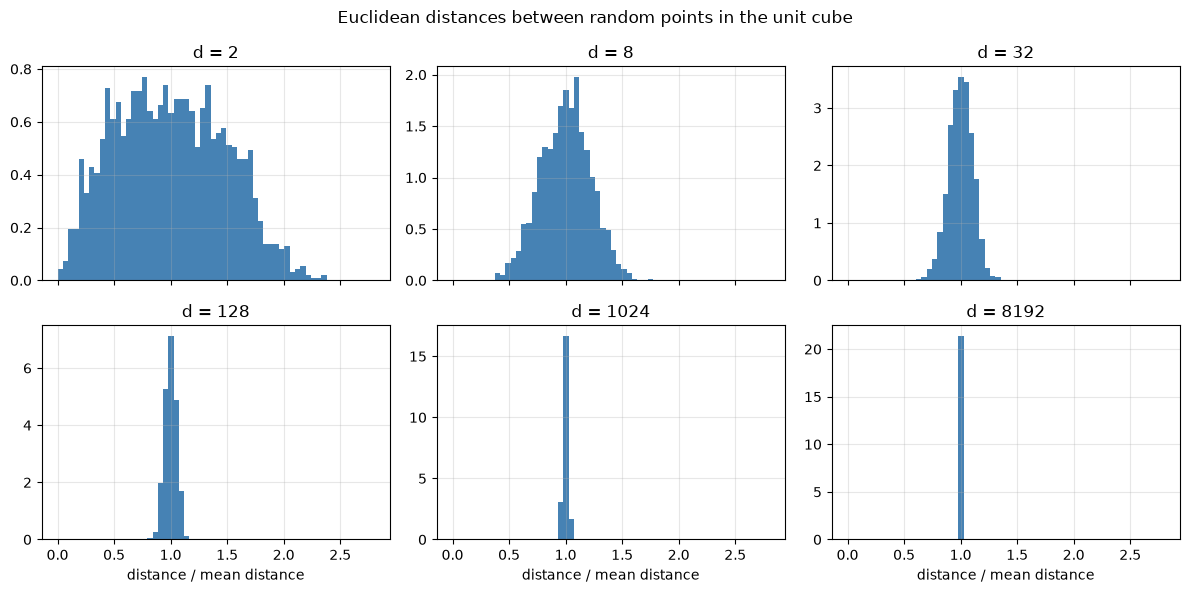

In [18]:
DIMS = [2, 8, 32, 128, 1024, 8192]
rng = np.random.default_rng(7)
pair_dist = {}
for d in DIMS:
    a = rng.random((2000, d), dtype=np.float32)
    b = rng.random((2000, d), dtype=np.float32)
    pair_dist[d] = np.linalg.norm(a - b, axis=1)

fig, axes = plt.subplots(2, 3, figsize=(12, 6), sharex=True)
for ax, d in zip(axes.flat, DIMS):
    ax.hist(pair_dist[d] / pair_dist[d].mean(), bins=60, range=(0, 2.8),
            color="steelblue", density=True)
    ax.set_title(f"d = {d}")
    ax.grid(alpha=0.3)
for ax in axes[1]:
    ax.set_xlabel("distance / mean distance")
plt.suptitle("Euclidean distances between random points in the unit cube")
plt.tight_layout()
plt.show()

In [19]:
rows = []
for d in DIMS:
    x = pair_dist[d]
    lo, hi = np.percentile(x, [0.5, 99.5])
    rows.append([d, f"{x.mean():.2f}", f"{np.sqrt(d / 6):.2f}", f"{x.std():.3f}", f"{hi - lo:.2f}"])
print_table(rows, headers=["d", "Mean distance", "√(d/6)", "Std. dev.", "Width of the middle 99%"])

|    d |   Mean distance |   √(d/6) |   Std. dev. |   Width of the middle 99% |
|-----:|----------------:|---------:|------------:|--------------------------:|
|    2 |            0.52 |     0.58 |       0.25  |                      1.07 |
|    8 |            1.14 |     1.15 |       0.25  |                      1.22 |
|   32 |            2.3  |     2.31 |       0.245 |                      1.28 |
|  128 |            4.6  |     4.62 |       0.243 |                      1.21 |
| 1024 |           13.06 |    13.06 |       0.244 |                      1.22 |
| 8192 |           36.95 |    36.95 |       0.234 |                      1.19 |

At $d = 8192$, the mean is about 36.9 and the standard deviation near 0.24, as in the
book. The middle 99 percent of all pairs fit into a band only a little more than one unit
wide.

## Consequence 1: trees can no longer prune

A tree over one million points can split only about 14 dimensions before a leaf holds one
disk page ($10^6 / 2^{14} \approx 61$ points). In all other dimensions, the leaf spans the
full range. No query is farther than $l_{\max} = 0.5\sqrt{14} \approx 1.87$ from such a
leaf. Once the expected nearest-neighbor distance exceeds $l_{\max}$, every leaf
intersects the NN-sphere and must be visited.

We measure the nearest-neighbor distance for one million uniform points. The points are
generated in chunks so the experiment fits into memory.

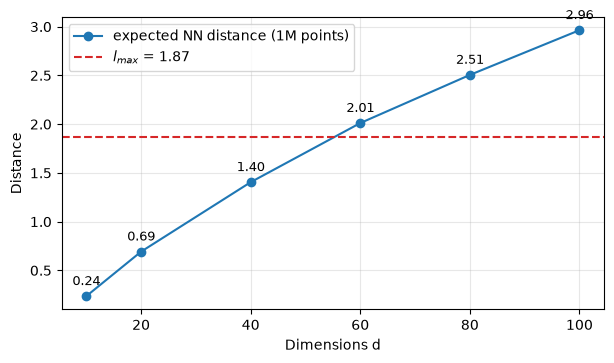

In [20]:
def expected_nn_distance(d, n_points=1_000_000, n_queries=50, chunk=100_000, seed=0):
    """Mean distance from random queries to their nearest neighbor among uniform points."""
    rng = np.random.default_rng(seed)
    Q = rng.random((n_queries, d), dtype=np.float32)
    best = np.full(n_queries, np.inf, dtype=np.float32)
    for _ in range(n_points // chunk):
        P = rng.random((chunk, d), dtype=np.float32)
        d2 = (Q ** 2).sum(1)[:, None] + (P ** 2).sum(1)[None, :] - 2 * Q @ P.T
        best = np.minimum(best, d2.min(axis=1))
    return float(np.sqrt(np.maximum(best, 0)).mean())

nn_dims = [10, 20, 40, 60, 80, 100]
nn_dist = [expected_nn_distance(d) for d in nn_dims]
l_max = 0.5 * np.sqrt(14)

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(nn_dims, nn_dist, "o-", label="expected NN distance (1M points)")
ax.axhline(l_max, color="tab:red", ls="--", label=f"$l_{{max}}$ = {l_max:.2f}")
for d, v in zip(nn_dims, nn_dist):
    ax.annotate(f"{v:.2f}", (d, v), textcoords="offset points", xytext=(-10, 8), fontsize=9)
ax.set_xlabel("Dimensions d")
ax.set_ylabel("Distance")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

The curve crosses $l_{\max}$ between $d = 40$ and $d = 60$, as in the book. From there on,
even the optimal algorithm must read every leaf, and the tree only adds overhead.

## Two more surprises (optional)

**The escaping sphere.** A square of side 2 has a circle of radius 1 at each corner. A
central circle touches all four. In $d$ dimensions, the center-to-corner distance is
$\sqrt{d}$, so the central sphere has radius $r = \sqrt{d} - 1$. The cube's faces are at
distance 1 from its center.

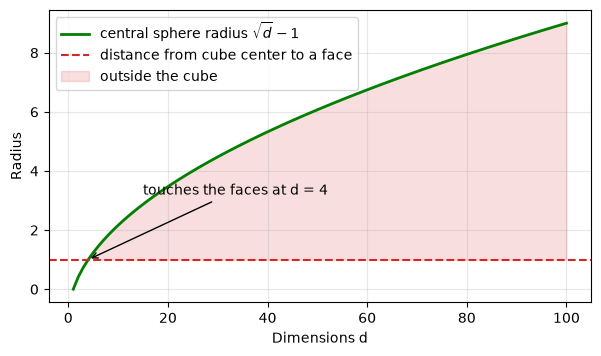

In [21]:
dims = np.arange(1, 101)
r = np.sqrt(dims) - 1

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(dims, r, color="green", lw=2, label=r"central sphere radius $\sqrt{d} - 1$")
ax.axhline(1, color="tab:red", ls="--", label="distance from cube center to a face")
ax.fill_between(dims, 1, r, where=r > 1, color="tab:red", alpha=0.15, label="outside the cube")
ax.annotate("touches the faces at d = 4", xy=(4, 1), xytext=(15, 3.2),
            arrowprops=dict(arrowstyle="->"))
ax.set_xlabel("Dimensions d")
ax.set_ylabel("Radius")
ax.legend(loc="upper left")
ax.grid(alpha=0.3)
plt.show()

At $d = 4$ the central sphere touches the faces of the cube. At $d = 100$, its radius is 9,
and the "inner" sphere reaches far outside the cube that is supposed to contain it.

**Where have all the points gone?** An inner cube of side 0.99 sits at the center of the
unit cube. It contains a fraction $0.99^d$ of uniform points: 98 percent in 2D, but only
$4.3 \times 10^{-5}$ at $d = 1000$. We check the formula with 100,000 random points.

In [22]:
rng = np.random.default_rng(11)
rows = []
for d in [2, 10, 100, 500]:
    pts = rng.random((100_000, d), dtype=np.float32)
    inside = np.all((pts > 0.005) & (pts < 0.995), axis=1).mean()
    rows.append([d, f"{inside:.4f}", f"{0.99 ** d:.4f}"])
print_table(rows, headers=["d", "Fraction inside (simulated)", "0.99^d"])

|   d |   Fraction inside (simulated) |   0.99^d |
|----:|------------------------------:|---------:|
|   2 |                        0.9798 |   0.9801 |
|  10 |                        0.9057 |   0.9044 |
| 100 |                        0.3706 |   0.366  |
| 500 |                        0.0069 |   0.0066 |

Almost every point lies close to one of the $2d$ faces. The center of a high-dimensional
space is empty.

## The dot product: losing direction

In 2D, a query and its best matches tend to share a quadrant. The high-dimensional
counterpart is an **orthant**, a region where every component has a fixed sign. There are
$2^d$ orthants, and two random vectors share one with probability $2^{-d}$. For one
billion vectors:

| Dimensions $d$ | Orthants $2^d$ | Vectors per orthant ($10^9 / 2^d$) |
|---|---|---|
| 10 | 1,024 | about 1,000,000 |
| 30 | about $1.1 \times 10^9$ | 0.93 |
| 100 | about $1.3 \times 10^{30}$ | $7.9 \times 10^{-22}$ |

We check the probability $2^{-d}$ on one million random pairs.

In [23]:
rng = np.random.default_rng(5)
rows = []
for d in [2, 4, 8, 12]:
    x = rng.standard_normal((1_000_000, d), dtype=np.float32)
    y = rng.standard_normal((1_000_000, d), dtype=np.float32)
    shared = np.all(np.sign(x) == np.sign(y), axis=1).mean()
    rows.append([d, f"{shared:.2e}", f"{2.0 ** -d:.2e}"])
print_table(rows, headers=["d", "Pairs sharing an orthant (simulated)", "2^-d"])

|   d |   Pairs sharing an orthant (simulated) |     2^-d |
|----:|---------------------------------------:|---------:|
|   2 |                               0.25     | 0.25     |
|   4 |                               0.0623   | 0.0625   |
|   8 |                               0.00389  | 0.00391  |
|  12 |                               0.000228 | 0.000244 |

## Dot products concentrate around zero

We draw pairs of random vectors with components uniform in $[-1, 1]$, normalize them to
unit length, and plot their dot product. At $d = 2$ the values spread from $-1$ to $1$. As
$d$ grows, they pile up around 0: random vectors become almost orthogonal.

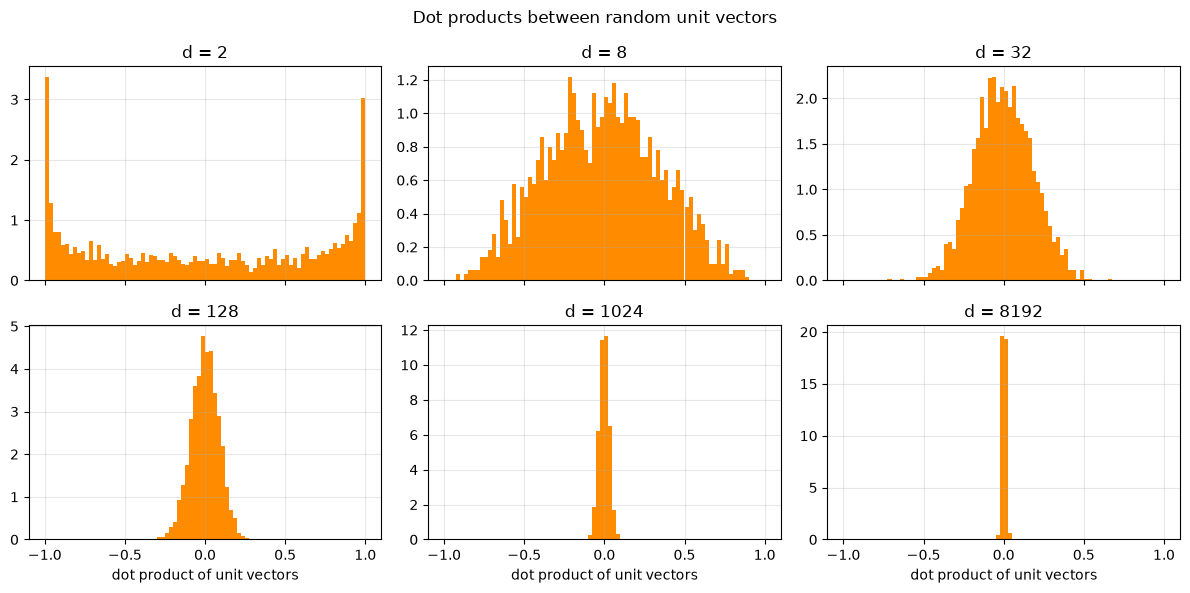

In [24]:
rng = np.random.default_rng(9)
fig, axes = plt.subplots(2, 3, figsize=(12, 6), sharex=True)
for ax, d in zip(axes.flat, DIMS):
    x = rng.uniform(-1, 1, (2000, d)).astype(np.float32)
    y = rng.uniform(-1, 1, (2000, d)).astype(np.float32)
    x /= np.linalg.norm(x, axis=1, keepdims=True)
    y /= np.linalg.norm(y, axis=1, keepdims=True)
    ax.hist((x * y).sum(axis=1), bins=80, range=(-1, 1), color="darkorange", density=True)
    ax.set_title(f"d = {d}")
    ax.grid(alpha=0.3)
for ax in axes[1]:
    ax.set_xlabel("dot product of unit vectors")
plt.suptitle("Dot products between random unit vectors")
plt.tight_layout()
plt.show()

The book explains the spike with a short statistical argument. The dot product of two
unnormalized vectors has a spread of $\sqrt{d}/3$, the vector lengths are about
$\sqrt{d/3}$, and the cosine therefore has a spread of about $1/\sqrt{d}$. We check every
step on 20,000 pairs, including the correlation between the dot product and the cosine.

In [25]:
rng = np.random.default_rng(42)
rows = []
for d in [2, 100, 768]:
    x = rng.uniform(-1, 1, (20_000, d)).astype(np.float32)
    y = rng.uniform(-1, 1, (20_000, d)).astype(np.float32)
    dot_xy = (x * y).sum(axis=1)
    len_x = np.linalg.norm(x, axis=1)
    cos_xy = dot_xy / (len_x * np.linalg.norm(y, axis=1))
    rows.append([d, f"{dot_xy.std():.2f}", f"{np.sqrt(d) / 3:.2f}",
                 f"{len_x.mean():.2f} ± {len_x.std():.2f}", f"{len_x.std() / len_x.mean():.1%}",
                 f"{cos_xy.std():.4f}", f"{1 / np.sqrt(d):.4f}",
                 f"{np.corrcoef(dot_xy, cos_xy)[0, 1]:.4f}"])
print_table(rows, headers=["d", "Std. dot", "√d/3", "Length", "Rel. length spread",
                           "Std. cos", "1/√d", "Corr(dot, cos)"])

|   d |   Std. dot |   √d/3 | Length       | Rel. length spread   |   Std. cos |   1/√d |   Corr(dot, cos) |
|----:|-----------:|-------:|:-------------|:---------------------|-----------:|-------:|-----------------:|
|   2 |       0.47 |   0.47 | 0.77 ± 0.29  | 37.4%                |     0.7064 | 0.7071 |           0.8778 |
| 100 |       3.35 |   3.33 | 5.77 ± 0.26  | 4.5%                 |     0.1006 | 0.1    |           0.998  |
| 768 |       9.2  |   9.24 | 16.00 ± 0.26 | 1.6%                 |     0.0359 | 0.0361 |           0.9997 |

Every prediction holds. The length spread stays near 0.26 in every dimension, so its
relative variation shrinks to a few percent. The dot product then ranks random vectors
almost exactly like the cosine: the correlation climbs from 0.88 in 2D to 0.9997 at
$d = 768$.

How high can a random match score? We search one million random unit vectors for the best
match to a random query at $d = 768$, again in chunks.

In [26]:
rng = np.random.default_rng(1)
d = 768
query = rng.standard_normal(d).astype(np.float32)
query /= np.linalg.norm(query)
best = -1.0
for _ in range(10):
    P = rng.standard_normal((100_000, d), dtype=np.float32)
    P /= np.linalg.norm(P, axis=1, keepdims=True)
    best = max(best, float((P @ query).max()))
display_md(f"**Best cosine among 1,000,000 random vectors at d = {d}:** {best:.3f} "
           f"(σ_cos = 1/√{d} = {1 / np.sqrt(d):.3f})")

**Best cosine among 1,000,000 random vectors at d = 768:** 0.190 (σ_cos = 1/√768 = 0.036)

Even the best of one million random vectors stays below 0.2. Against this background, a
real match must stand out.

## Payoff: real embeddings stand out, but the top hits crowd together

The analysis so far assumed random, uniform data. Real embeddings form clusters, and the
book claims that relevant documents stand out as outliers, while the top few hits still
lie close together. We test this on 15,000 TREC-COVID abstracts and the 50 TREC-COVID
queries, embedded with Qwen3-Embedding-0.6B at 256 dimensions. We use the same sample as
the ANN benchmark demo (ch06-04). As a baseline, we draw 15,000 random unit vectors of the
same dimension.

In [27]:
SAMPLE = Path("eval/ch06_ann/sample_256.npz")
if not SAMPLE.exists():
    raise FileNotFoundError(f"{SAMPLE} is missing; it ships with the ch06 demos (see demos/README.md).")

sample = np.load(SAMPLE)
docs_real = sample["docs"].astype(np.float32)
queries = sample["queries"].astype(np.float32)
docs_real /= np.linalg.norm(docs_real, axis=1, keepdims=True)
queries /= np.linalg.norm(queries, axis=1, keepdims=True)

rng = np.random.default_rng(0)
docs_random = rng.standard_normal(docs_real.shape).astype(np.float32)
docs_random /= np.linalg.norm(docs_random, axis=1, keepdims=True)

def score_profile(Dm, Qm):
    """Background and top-k statistics of the query-document cosine scores."""
    S = Qm @ Dm.T
    top = -np.sort(-S, axis=1)
    l2 = np.sqrt(np.maximum(2 - 2 * S, 0))
    return {
        "mean": S.mean(), "std": S.std(),
        "top 1": top[:, 0].mean(), "top 10": top[:, 9].mean(),
        "gap": (top[:, 0] - top[:, 9]).mean(),
        "contrast": ((l2.max(axis=1) - l2.min(axis=1)) / l2.min(axis=1)).mean(),
    }

def profile_table(profiles, label):
    print_table(
        [[name, f"{p['mean']:.3f} ± {p['std']:.3f}", f"{p['top 1']:.3f}", f"{p['top 10']:.3f}",
          f"{p['gap']:.3f}", f"{p['contrast']:.2f}"] for name, p in profiles.items()],
        headers=[label, "Background cosine", "Mean top 1", "Mean top 10",
                 "Gap top 1 to top 10", "L2 contrast"],
    )

rand, real = score_profile(docs_random, queries), score_profile(docs_real, queries)
profile_table({"Random unit vectors": rand, "TREC-COVID embeddings": real}, "Collection (256 d)")
display_md(
    f"- The real top 10 lie **{(real['top 10'] - rand['mean']) / rand['std']:.0f} standard deviations** "
    f"of the random background above its mean; the best random vector reaches only {rand['top 1']:.2f}.\n"
    f"- The gap between the real top 1 and top 10 is {real['gap']:.3f}, "
    f"**{real['gap'] / real['std']:.1f} standard deviations** of the real background."
)

| Collection (256 d)    | Background cosine   |   Mean top 1 |   Mean top 10 |   Gap top 1 to top 10 |   L2 contrast |
|:----------------------|:--------------------|-------------:|--------------:|----------------------:|--------------:|
| Random unit vectors   | 0.001 ± 0.063       |        0.24  |         0.201 |                 0.039 |          0.28 |
| TREC-COVID embeddings | 0.394 ± 0.122       |        0.773 |         0.716 |                 0.058 |          1.19 |

- The real top 10 lie **11 standard deviations** of the random background above its mean; the best random vector reaches only 0.24.
- The gap between the real top 1 and top 10 is 0.058, **0.5 standard deviations** of the real background.

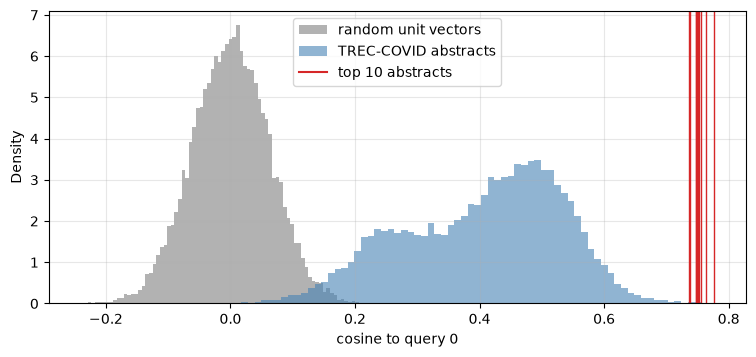

In [28]:
qi = 0
s_real = docs_real @ queries[qi]
s_rand = docs_random @ queries[qi]
top10 = np.sort(s_real)[-10:]

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.hist(s_rand, bins=80, alpha=0.6, color="gray", density=True, label="random unit vectors")
ax.hist(s_real, bins=80, alpha=0.6, color="steelblue", density=True, label="TREC-COVID abstracts")
for s in top10:
    ax.axvline(s, color="tab:red", lw=1)
ax.plot([], [], color="tab:red", label="top 10 abstracts")
ax.set_xlabel(f"cosine to query {qi}")
ax.set_ylabel("Density")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

Two things are visible at once. Real embeddings keep far more contrast than random
vectors, and the best abstracts lie far above the narrow band that random vectors occupy.
This is why vector search works in high dimensions at all. But the top 10 crowd together
in a narrow band at the right end. The highest score is one good match among several
that are almost equally close. (Real embeddings also share a common direction, so their
background is centered well above 0. Only the spread matters for ranking.)

<div style="border-left: 4px solid #C8102E; background: rgba(200, 16, 46, 0.06); padding: 0.6em 0.9em; margin: 0.6em 0; border-radius: 4px;">
<strong style="color:#C8102E; text-transform:uppercase; font-size:0.78em; letter-spacing:0.06em;">Good matches instead of the best match</strong><br>
In high dimensions, distances lose their contrast and trees end up visiting every leaf. Real data keeps vector search meaningful: relevant documents stand out from the background. Among them, however, the top scores lie so close together that the exact nearest neighbor carries little extra meaning. A retriever only needs to find good matches and pass them to a reranker. This opens the door to the approximate methods of the next demo (ch06-02).
</div>

## Summary

| Concept | Key point |
|---|---|
| Dot product vs. cosine | The dot product rewards long vectors; cosine rewards direction only |
| Normalized documents | Store $\hat{\mathbf{d}}_i$; the query length then scales all scores equally and leaves the ranking unchanged |
| Unit sphere | $\lVert \hat{\mathbf{q}} - \hat{\mathbf{d}}_i \rVert^2 = 2 - 2\,\hat{\mathbf{q}} \cdot \hat{\mathbf{d}}_i$: Euclidean and cosine rank alike |
| Perceptual features | Come with their own distance; swapping the comparison changes the ranking |
| Comparable dimensions | Divide by image size; Gaussian-normalize mixed features; whiten for a quadratic distance |
| Loss of contrast | $(\delta_{\max} - \delta_{\min}) / \delta_{\min} \to 0$; trees stop pruning between $d = 40$ and $60$ for 1M points |
| Concentration of cosine | $\sigma_{\cos} \approx 1/\sqrt{d}$; random vectors are almost orthogonal |
| Real data | Relevant documents stand out, but the top hits crowd together: good matches suffice |

## Try it yourself

**1. Fewer points, other dimensions.** The contrast depends on the number of points as
well as on the dimension. Rerun the experiment with 1,000 points instead of 10,000, or add
dimensions in between.

In [29]:
print_table(contrast_table([2, 10, 50, 100, 1000], n_points=1_000),
            headers=["d", "Contrast L1", "Contrast L2", "Mean L2 distance", "Std. dev. L2"])

|    d |   Contrast L1 |   Contrast L2 |   Mean L2 distance |   Std. dev. L2 |
|-----:|--------------:|--------------:|-------------------:|---------------:|
|    2 |        106    |         96    |               0.5  |           0.22 |
|   10 |          3.49 |          2.76 |               1.27 |           0.23 |
|   50 |          0.86 |          0.67 |               2.88 |           0.22 |
|  100 |          0.55 |          0.43 |               4.07 |           0.22 |
| 1000 |          0.14 |          0.12 |              12.89 |           0.22 |

**2. Another query tile.** Pick any tile name from the collection grid and compare its
neighbors under the color-only, the mixed, and the Gaussian-normalized features. Dark
tiles such as `F10` or bright sky tiles such as `M04` behave differently.

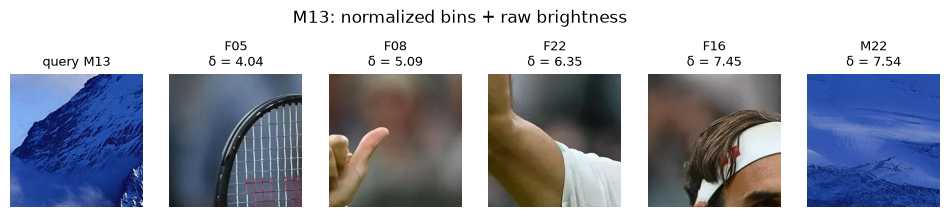

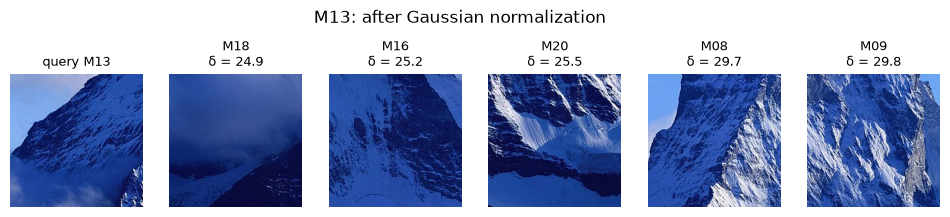

In [30]:
show_neighbors("M13", mixed, title="M13: normalized bins + raw brightness")
show_neighbors("M13", gauss, title="M13: after Gaussian normalization");

**3. Fewer dimensions for real embeddings.** Qwen3-Embedding is Matryoshka-trained, so its
first components carry most of the meaning. Truncate `docs_real` and `queries` to the first
64 components, normalize them again, and compare the profile with the full 256 dimensions.
Does the gap between the top 1 and the top 10 grow or shrink?

In [31]:
def truncated(E, dim):
    E = E[:, :dim]
    return E / np.linalg.norm(E, axis=1, keepdims=True)

profile_table({dim: score_profile(truncated(docs_real, dim), truncated(queries, dim))
               for dim in [256, 128, 64, 32]}, "Dimensions")

|   Dimensions | Background cosine   |   Mean top 1 |   Mean top 10 |   Gap top 1 to top 10 |   L2 contrast |
|-------------:|:--------------------|-------------:|--------------:|----------------------:|--------------:|
|          256 | 0.394 ± 0.122       |        0.773 |         0.716 |                 0.058 |          1.19 |
|          128 | 0.409 ± 0.133       |        0.797 |         0.743 |                 0.054 |          1.4  |
|           64 | 0.472 ± 0.148       |        0.848 |         0.802 |                 0.046 |          1.84 |
|           32 | 0.510 ± 0.160       |        0.891 |         0.85  |                 0.041 |          2.48 |